In [1]:
import os
from scipy.io import loadmat
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import re

In [2]:
import warnings
warnings.filterwarnings('ignore')
pd.options.mode.chained_assignment = None

### 1. Read FC

In [3]:
mat_files = [f for f in os.listdir('.') if f.endswith('_C_results.mat')]

data_dict = {}

for file in mat_files:
    data = loadmat(file)
    data_dict[file] = data  

for filename, content in data_dict.items():
    print(f"{filename}: keys = {list(content.keys())}")

94_C_results.mat: keys = ['__header__', '__version__', '__globals__', 'C_trace_region', 'C_trace_region2', 'timestamps', 'unique_area']
370_C_results.mat: keys = ['__header__', '__version__', '__globals__', 'C_trace_region', 'C_trace_region2', 'timestamps', 'unique_area']
369_C_results.mat: keys = ['__header__', '__version__', '__globals__', 'C_trace_region', 'C_trace_region2', 'timestamps', 'unique_area']
371_C_results.mat: keys = ['__header__', '__version__', '__globals__', 'C_trace_region', 'C_trace_region2', 'timestamps', 'unique_area']
367_C_results.mat: keys = ['__header__', '__version__', '__globals__', 'C_trace_region', 'C_trace_region2', 'timestamps', 'unique_area']


In [4]:
def get_region_data(file_name, time_index, region_index, average=False):
    mat = data_dict[file_name]
    
    if 'C_trace_region2' not in mat:
        raise KeyError(f"'C_trace_region2' not found in {file_name}")
    if 'unique_area' not in mat:
        raise KeyError(f"'unique_area' not found in {file_name}")
    
    trace = mat['C_trace_region2']
    unique_area = mat['unique_area']
    
    region_data = trace[time_index, region_index]
    region_label = unique_area[0][region_index]
    
    if average:
        avg_data = np.mean(region_data, axis=0)
        return avg_data, region_label
    else:
        return region_data, region_label

In [5]:
region_trace, region_label = get_region_data('371_C_results.mat', 0, 2, average=True)
print(f"Region Trace: {region_trace}")
print(f"Region Label: {region_label}")

Region Trace: [3.0323935 3.0573952 3.0094352 ... 2.2861505 2.214661  2.2247381]
Region Label: ['SSp-bfd1']


In [6]:
from scipy.signal import coherence

File_list = ['94_C_results.mat','370_C_results.mat','369_C_results.mat','371_C_results.mat','367_C_results.mat']

def calculate_correlation(file_name):
    mat = data_dict[file_name]
    
    if 'unique_area' not in mat:
        raise KeyError(f"'unique_area' not found in {file_name}")
    
    unique_area = mat['unique_area']
    num_regions = len(unique_area[0])
    num_time_points = 22
    
    correlation_dict = {}

    for time_stage in range(num_time_points):
        correlation_matrix = np.zeros((num_regions, num_regions))
        
        for region_index1 in range(num_regions):
            for region_index2 in range(region_index1, num_regions):  # compute only upper triangle
                region_data1, _ = get_region_data(file_name, time_stage, region_index1, average=True)
                region_data2, _ = get_region_data(file_name, time_stage, region_index2, average=True)
                
                region_data1 = np.array(region_data1, dtype=float)
                region_data2 = np.array(region_data2, dtype=float)
                
                #correlation, _ = pearsonr(region_data1, region_data2)
                correlation, _ = pearsonr(region_data1, region_data2)
                correlation_matrix[region_index1, region_index2] = correlation
                correlation_matrix[region_index2, region_index1] = correlation  
        
        # Min-max normalization to [0, 1]
        min_val = np.min(correlation_matrix)
        max_val = np.max(correlation_matrix)
        if max_val != min_val:
            normalized_matrix = (correlation_matrix - min_val) / (max_val - min_val)
        else:
            normalized_matrix = np.zeros_like(correlation_matrix)
        
        correlation_dict[time_stage] = normalized_matrix
    
    return correlation_dict, unique_area

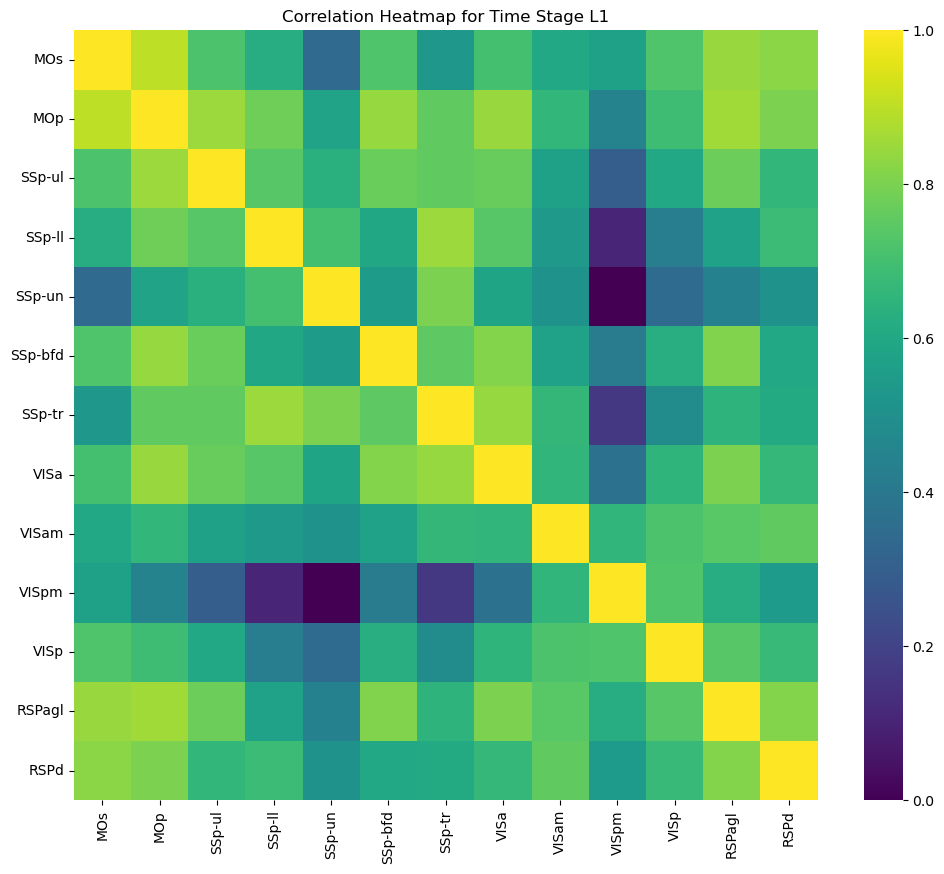

In [7]:
from scipy.stats import pearsonr

def plot_correlation_heatmap(correlation_dict, time_stage, unique_area, stage_type, NAME='out'):
    correlation_matrix = correlation_dict.get(time_stage)
    
    if correlation_matrix is None:
        print(f"No data available for time stage {time_stage}")
        return
    
    region_labels = [re.sub(r'1$', '', label[0]) for label in unique_area[0]]
    
    desired_order = ['MOs','MOp','SSp-ul','SSp-ll','SSp-un','SSp-bfd','SSp-tr',
                     'VISa','VISam','VISpm','VISp','RSPagl','RSPd']

    try:
        indices = [region_labels.index(label) for label in desired_order]
    except ValueError as e:
        print(f"Error: {e}. One or more desired labels not found in region_labels.")
        return

    reordered_matrix = correlation_matrix[np.ix_(indices, indices)]
    reordered_labels = [region_labels[i] for i in indices]
    
    plt.figure(figsize=(12, 10))
    sns.heatmap(reordered_matrix, annot=False, cmap='viridis', fmt='.2f', 
                xticklabels=reordered_labels, yticklabels=reordered_labels, 
                )
    
    plt.title(f'Correlation Heatmap for Time Stage {stage_type}')
    plt.xlabel('')
    plt.ylabel('')
    plt.xticks(rotation=90)
    plt.yticks(rotation=0)
    plt.savefig('{}.tif'.format(NAME), format='tiff', dpi=300)
    plt.show()


correlation_dict, unique_area = calculate_correlation(File_list[0])
plot_correlation_heatmap(correlation_dict, 21, unique_area, stage_type="L1")

In [8]:
import pickle
import numpy as np
import re

desired_order = ['MOs','MOp','SSp-ul','SSp-ll','SSp-un','SSp-bfd','SSp-tr',
                 'VISa','VISam','VISpm','VISp','RSPagl','RSPd']

selected_indices = [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21]
#selected_indices = [1]
saved_data = {}

for j in range(5):
    correlation_dict_all, unique_area = calculate_correlation(File_list[j])
    region_labels = [re.sub(r'1$', '', label[0]) for label in unique_area[0]]

    try:
        indices = [region_labels.index(label) for label in desired_order]
    except ValueError as e:
        print(f"Error in file {j}: {e}")
        continue

    saved_data[j] = {}
    for idx in selected_indices:
        if idx not in correlation_dict_all:
            print(f"Time index {idx} not found in file {j}")
            continue

        matrix = correlation_dict_all[idx]
        filtered_matrix = matrix[np.ix_(indices, indices)]

        filtered_corr_dict = {idx: filtered_matrix}
        filtered_unique_area = [[unique_area[0][i] for i in indices]]

        saved_data[j][idx] = {
            'correlation_dict': filtered_corr_dict,
            'unique_area': filtered_unique_area
        }

with open('FC.pkl', 'wb') as f:
    pickle.dump(saved_data, f)


#### 1.1 Calculate average correlation

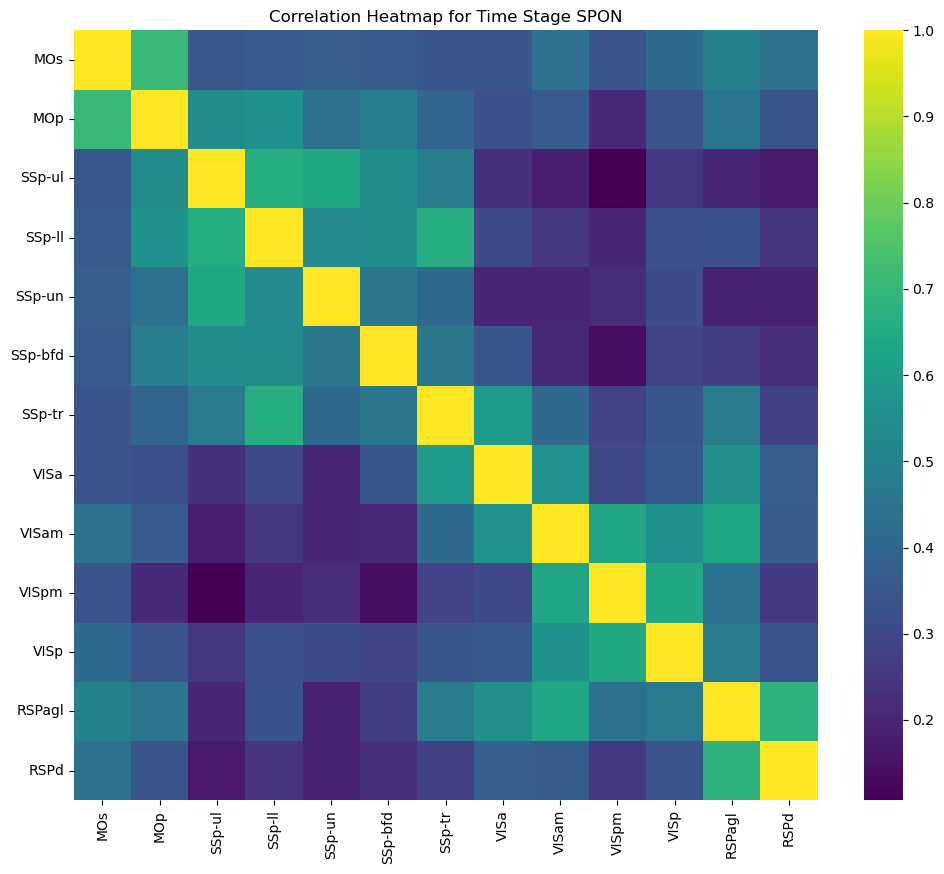

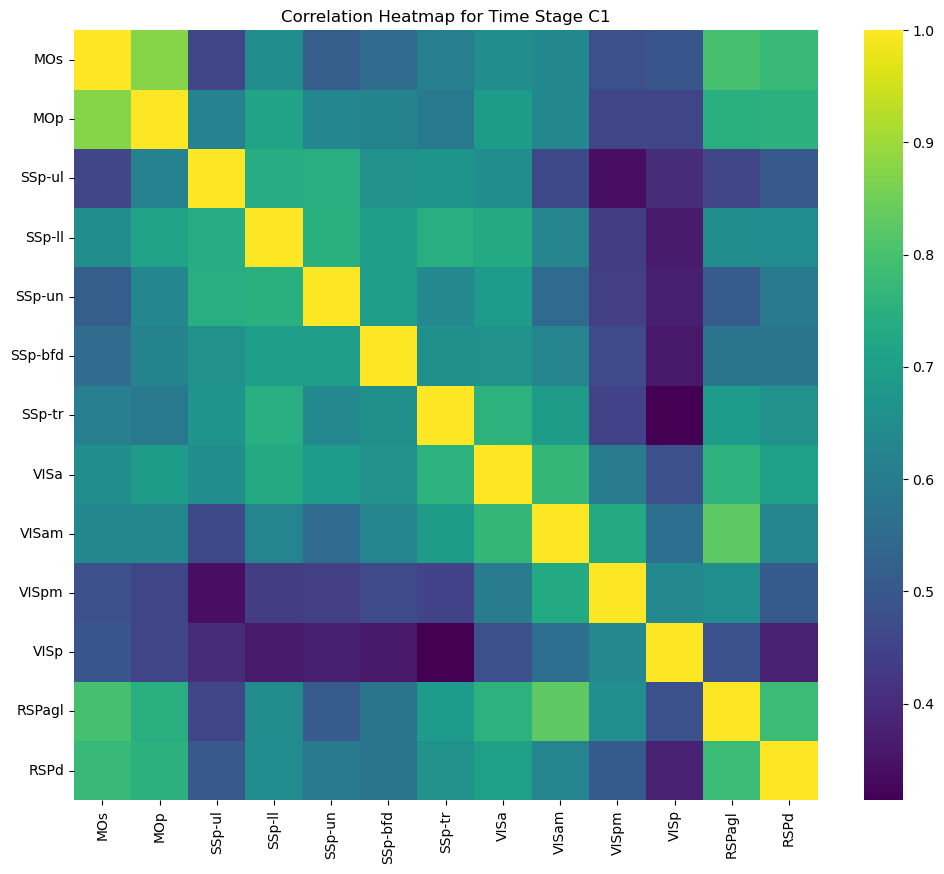

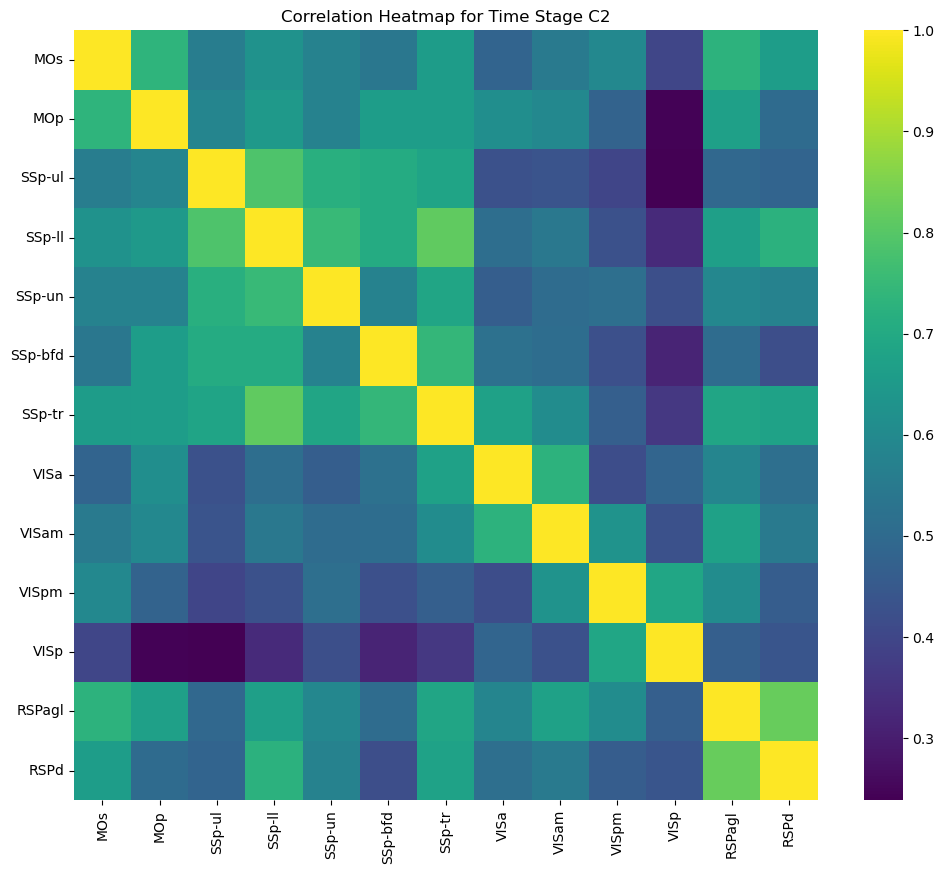

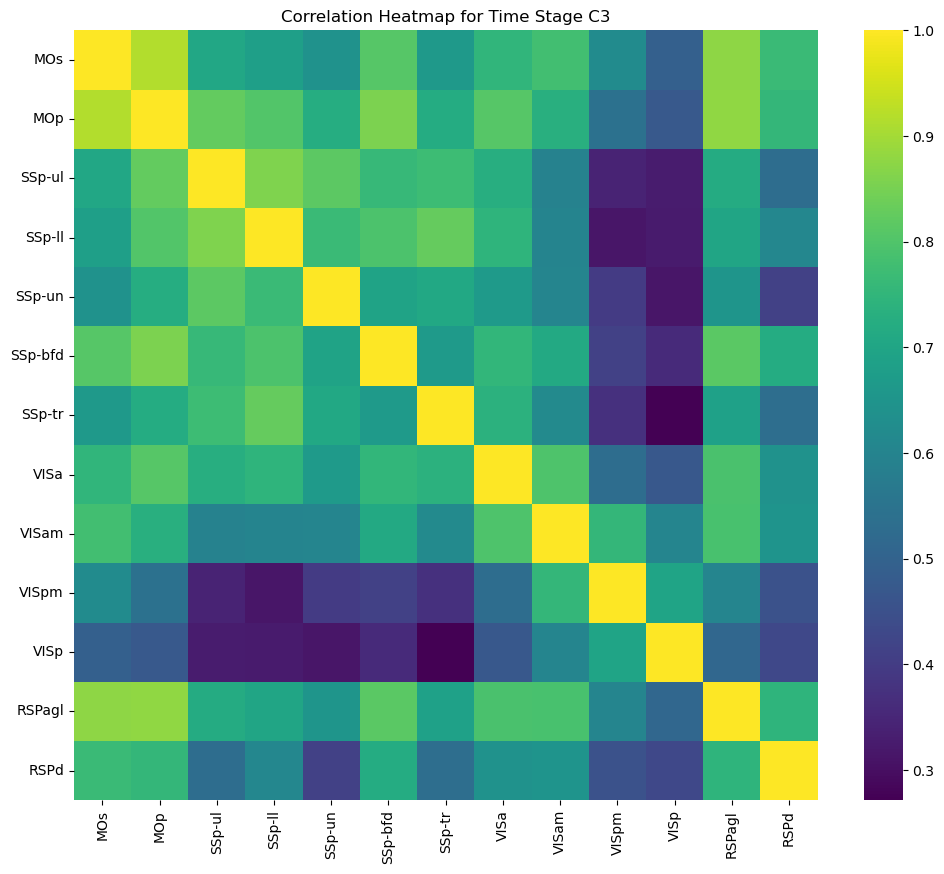

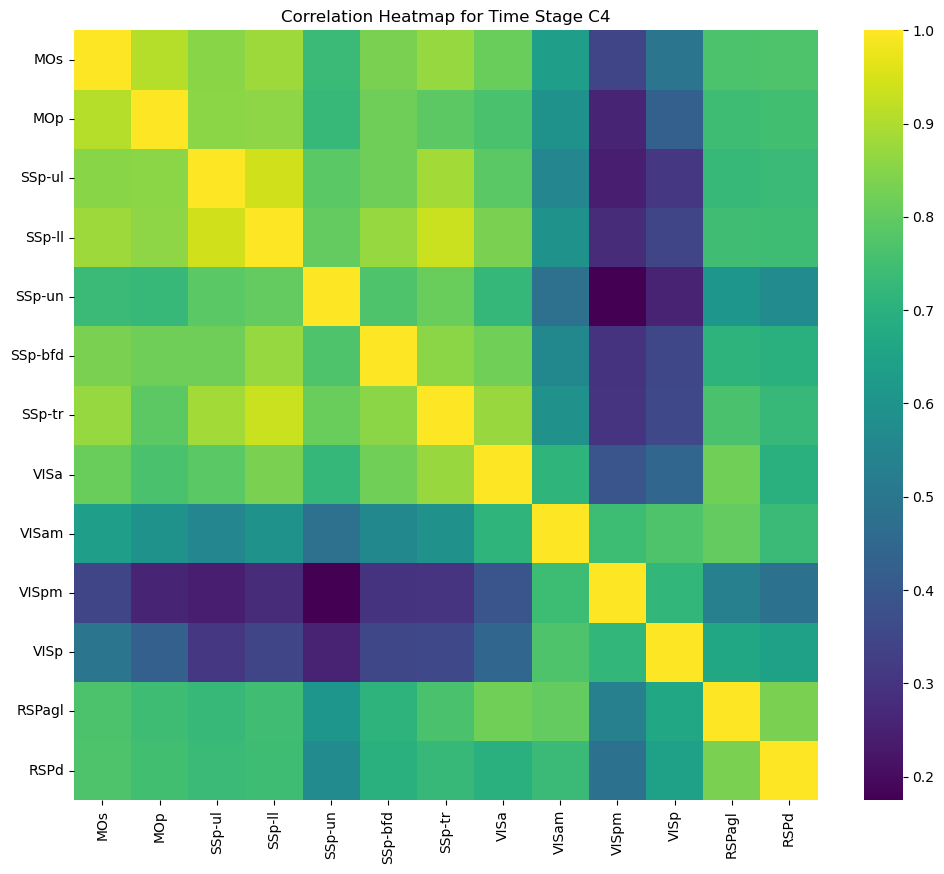

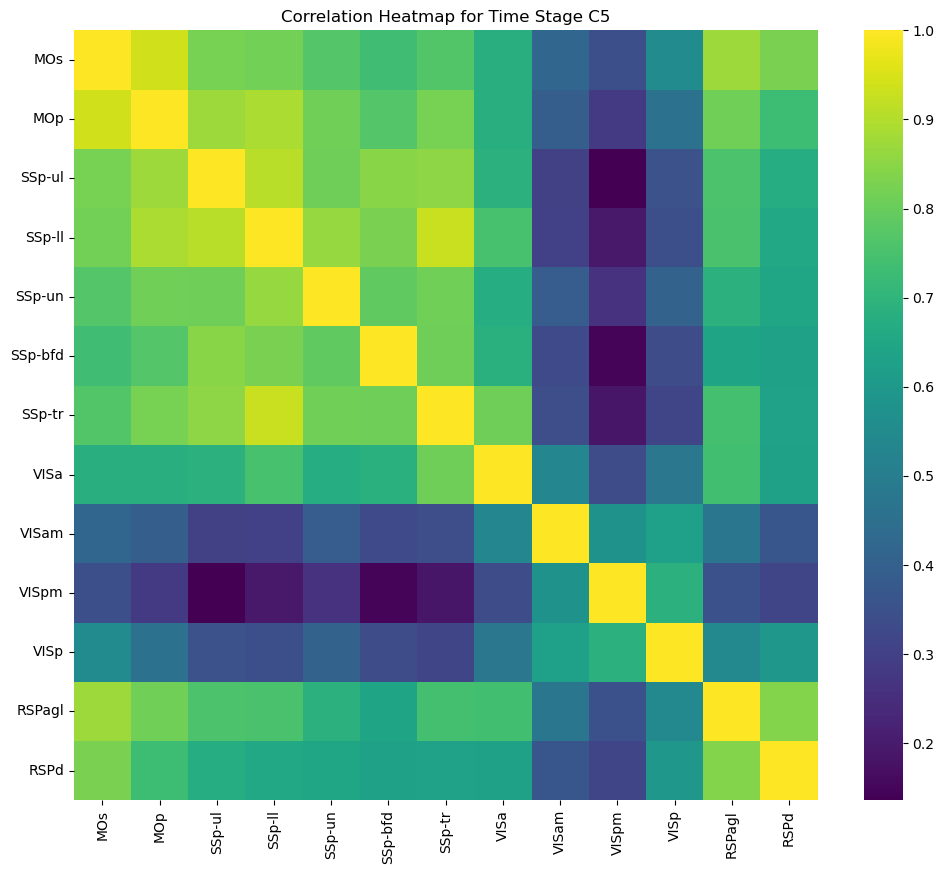

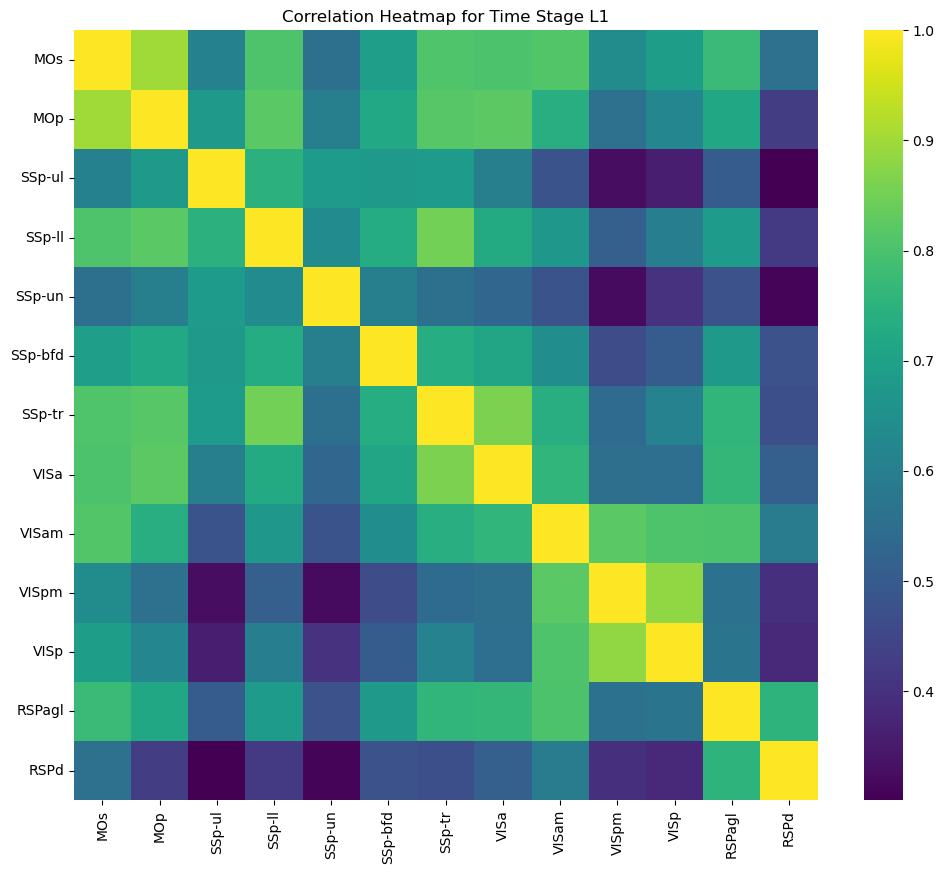

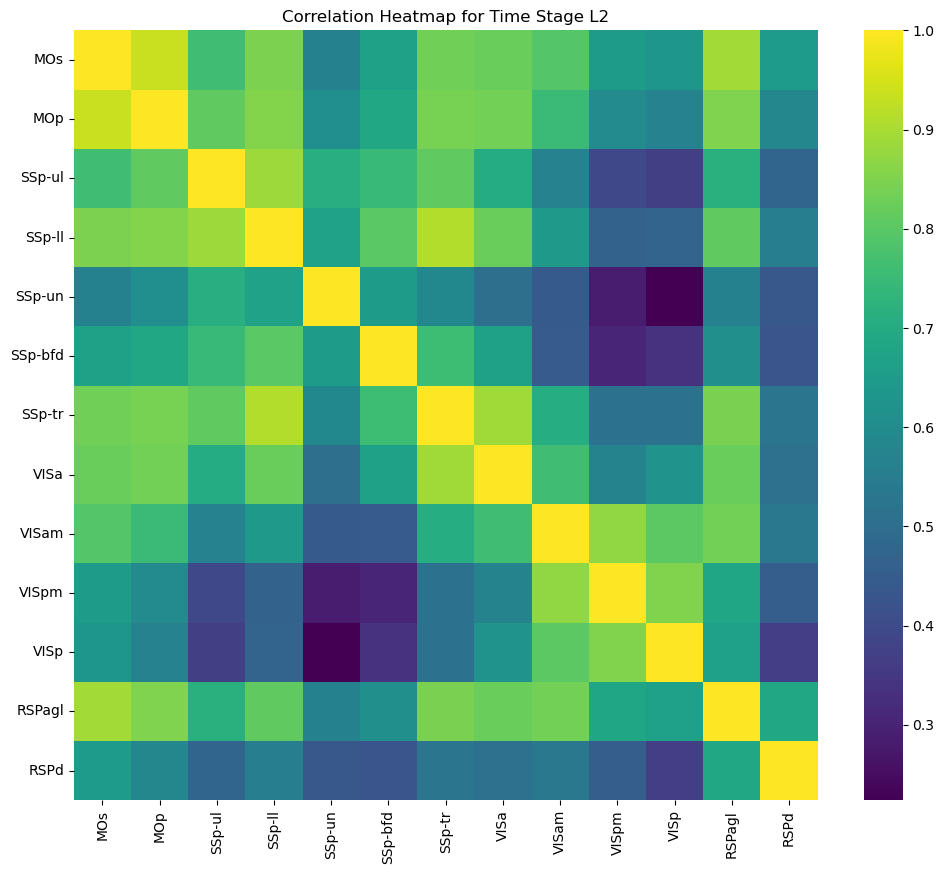

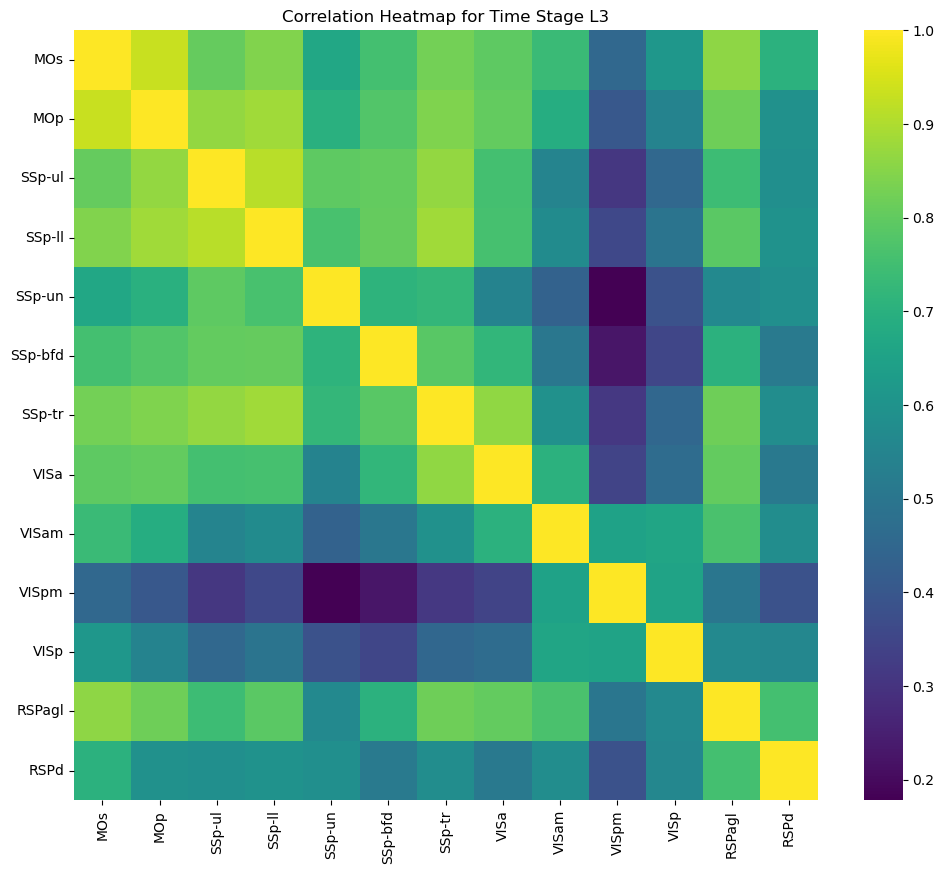

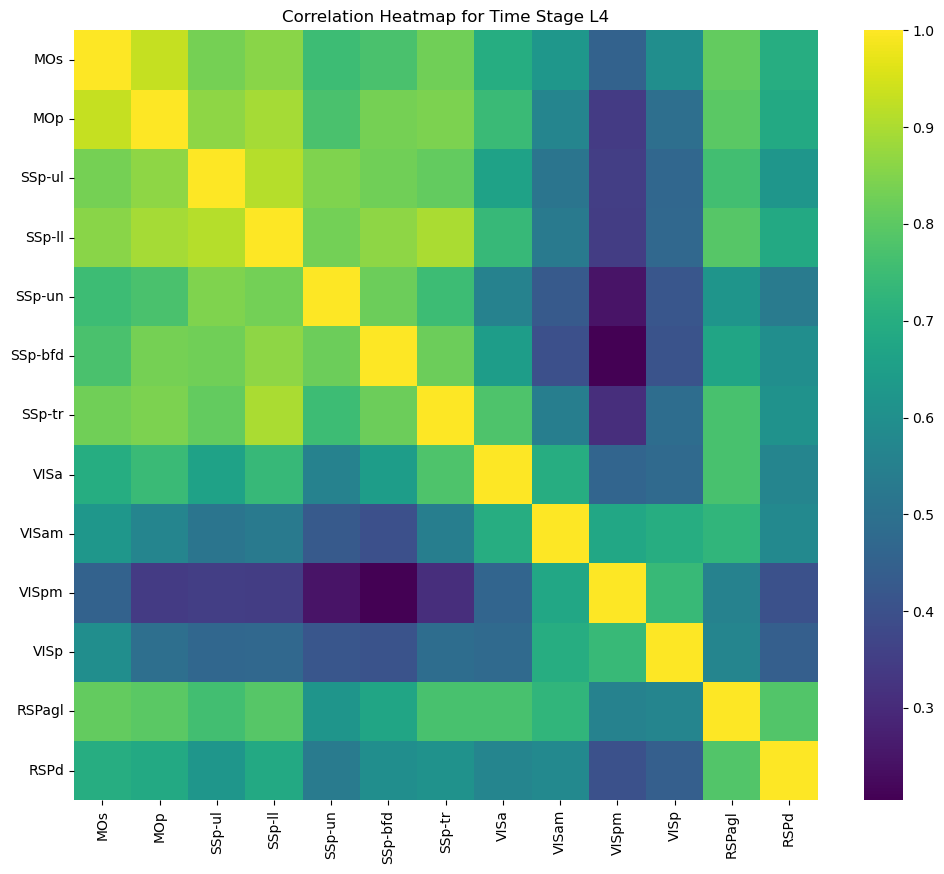

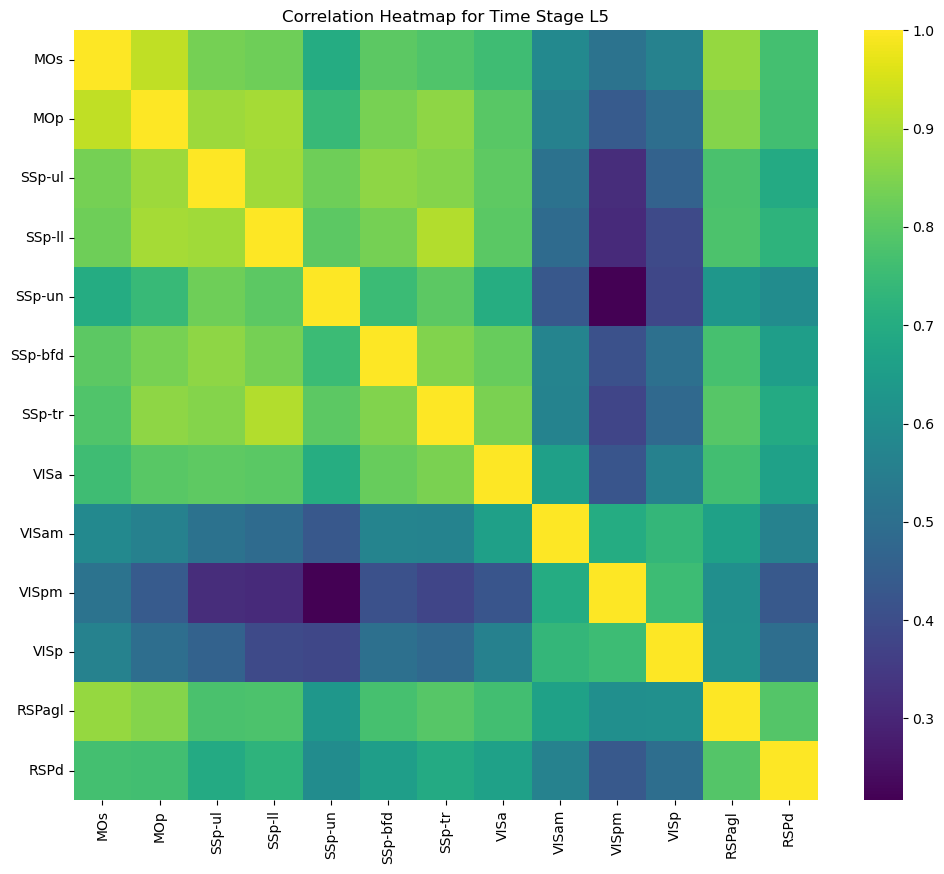

In [9]:
def calculate_average_correlation(File_list, time_stage):
    matrices = []
    unique_area_reference = None

    for i in range(5):  # File_list[0] to File_list[4]
        correlation_dict, unique_area = calculate_correlation(File_list[i])
        matrix = correlation_dict.get(time_stage)

        if matrix is not None:
            matrices.append(matrix)
            if unique_area_reference is None:
                unique_area_reference = unique_area
        else:
            print(f"Warning: No data for time stage {time_stage} in file {File_list[i]}")

    if not matrices:
        print(f"No valid correlation matrices found for time stage {time_stage}")
        return None, None

    avg_matrix = np.mean(matrices, axis=0)
    avg_correlation_dict = {time_stage: avg_matrix}

    return avg_correlation_dict, unique_area_reference

#avg_correlation_dict, unique_area = calculate_average_correlation(File_list, time_stage=21)

#if avg_correlation_dict is not None:
#    plot_correlation_heatmap(avg_correlation_dict, time_stage=21, unique_area=unique_area, stage_type="L5")

i_list_C = [2, 6, 10, 14, 18]
i_list_L = [5, 9, 13, 17, 21]

i = 1
avg_correlation_dict, unique_area = calculate_average_correlation(File_list, time_stage=i)
if avg_correlation_dict is not None:
    stage_type = "SPON"
    plot_correlation_heatmap(avg_correlation_dict, time_stage=i, unique_area=unique_area, stage_type=stage_type, NAME=stage_type)

for idx, i in enumerate(i_list_C):
    avg_correlation_dict, unique_area = calculate_average_correlation(File_list, time_stage=i)
    if avg_correlation_dict is not None:
        stage_type = f"C{idx + 1}"
        plot_correlation_heatmap(avg_correlation_dict, time_stage=i, unique_area=unique_area, stage_type=stage_type, NAME=stage_type)

for idx, i in enumerate(i_list_L):
    avg_correlation_dict, unique_area = calculate_average_correlation(File_list, time_stage=i)
    if avg_correlation_dict is not None:
        stage_type = f"L{idx + 1}"
        plot_correlation_heatmap(avg_correlation_dict, time_stage=i, unique_area=unique_area, stage_type=stage_type, NAME=stage_type)

#### 1.2 Plot Gif

In [17]:
import os
import imageio
from IPython.display import Image
import matplotlib
import matplotlib.pyplot as plt

os.makedirs("heatmap_frames", exist_ok=True)
frame_paths = []

def plot_correlation_heatmap2(correlation_dict, time_stage, unique_area):
    correlation_matrix = correlation_dict.get(time_stage)
    
    if correlation_matrix is None:
        print(f"No data available for time stage {time_stage}")
        return
    
    region_labels = [re.sub(r'1$', '', label[0]) for label in unique_area[0]]
    
    desired_order = ['MOs','MOp','SSp-ul','SSp-ll','SSp-un','SSp-bfd','SSp-tr',
                     'VISa','VISam','VISpm','VISp','RSPagl','RSPd']

    try:
        indices = [region_labels.index(label) for label in desired_order]
    except ValueError as e:
        print(f"Error: {e}. One or more desired labels not found in region_labels.")
        return

    reordered_matrix = correlation_matrix[np.ix_(indices, indices)]
    reordered_labels = [region_labels[i] for i in indices]
    
    plt.figure(figsize=(12, 10))
    sns.heatmap(reordered_matrix, annot=False, cmap='viridis', fmt='.2f', 
                xticklabels=reordered_labels, yticklabels=reordered_labels, 
                vmin=0, vmax=1)
    
    plt.title(f'Correlation Heatmap for Time Stage {time_stage}')
    plt.xlabel('Region Label')
    plt.ylabel('Region Label')
    plt.xticks(rotation=90)
    plt.yticks(rotation=0)

for t in range(1, 22):
    plot_correlation_heatmap2(correlation_dict, t, unique_area)
    
    save_path = f"heatmap_frames/frame_{t:02d}.png"
    plt.savefig(save_path, bbox_inches='tight', dpi=150)
    plt.close()  
    
    frame_paths.append(save_path)

gif_path = "correlation_heatmap.gif"
with imageio.get_writer(gif_path, mode='I', duration=1) as writer:
    for path in frame_paths:
        image = imageio.imread(path)
        writer.append_data(image)


### 2. Read SC

In [10]:
df = pd.read_excel('SEU_net_wo_corticalLayers.xlsx', header=1, index_col=1)
df = df.iloc[:, 1:]
df

,FRP,MOp,MOs,SSp-n,SSp-bfd,SSp-ll,SSp-m,SSp-ul,SSp-tr,SSp-un,...,MD,SMT,PVT,RE,CM,RT,PSV,PB,TRN,PRNr
FRP,0.000000,0.000000,2.028292,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0,0,0,0.000000
MOp,0.625221,1.992551,1.765525,0.930700,0.678581,1.968629,1.024268,0.953173,1.600363,0.961477,...,0.000000,0.000000,0.0,0.000000,0.0,0.861023,0,0,0,0.875238
MOs,1.417198,1.381516,1.645074,0.670320,2.725806,0.853611,1.209884,1.446972,0.000000,0.000000,...,0.000000,1.621683,0.0,0.000000,0.0,0.768877,0,0,0,0.000000
SSp-n,0.000000,0.789537,1.283165,1.795210,1.301726,0.000000,1.947067,2.399795,0.000000,1.158404,...,0.000000,0.000000,0.0,0.000000,0.0,0.810396,0,0,0,0.000000
SSp-bfd,0.000000,1.159698,0.766737,1.669994,1.934520,0.447926,1.166723,0.869816,3.467967,1.047941,...,0.000000,0.000000,0.0,0.000000,0.0,0.191446,0,0,0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RT,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.514522,2.131420,0.0,4.582369,0.0,0.762490,0,0,0,0.000000
PSV,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0,0,0,0.720976
PB,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0,0,0,1.214098
TRN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0,0,0,0.000000


In [11]:
desired_order = ['MOs','MOp','SSp-ul','SSp-ll','SSp-un','SSp-bfd','SSp-tr',
                 'VISa','VISam','VISpm','VISp','RSPagl','RSPd']
label_list = [re.sub(r'1$', '', label[0]) for label in unique_area[0]]
filtered_df = df.loc[df.index.intersection(label_list), df.columns.intersection(label_list)]
filtered_df_ordered = filtered_df.loc[desired_order, desired_order]
filtered_df_ordered

,MOs,MOp,SSp-ul,SSp-ll,SSp-un,SSp-bfd,SSp-tr,VISa,VISam,VISpm,VISp,RSPagl,RSPd
MOs,1.645074,1.381516,1.446972,0.853611,0.000000,2.725806,0.000000,0.000000,0.000000,0.000000,0.867938,0.000000,0.000000
MOp,1.765525,1.992551,0.953173,1.968629,0.961477,0.678581,1.600363,0.000000,0.000000,0.000000,0.335160,2.211280,5.063436
SSp-ul,3.054838,1.443828,2.481238,1.711227,1.348156,0.598507,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
SSp-ll,0.689180,1.950709,1.395424,3.108903,0.864234,0.643465,2.154667,0.000000,0.000000,0.000000,0.000000,0.712695,0.000000
SSp-un,0.540600,0.588739,1.983733,0.393314,1.666413,2.047131,0.309392,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
SSp-bfd,0.766737,1.159698,0.869816,0.447926,1.047941,1.934520,3.467967,1.000840,0.348838,0.000000,0.480395,0.461558,0.000000
SSp-tr,1.958032,1.591901,11.478469,9.307183,1.219740,1.266143,0.423247,0.000000,0.000000,0.000000,1.153103,6.914832,0.000000
VISa,0.253308,0.000000,0.000000,0.000000,0.000000,1.174191,1.710483,0.000000,0.000000,0.000000,0.375386,3.327527,1.394746
VISam,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.517546,0.000000,6.803200,1.633869,0.441544,2.684360,0.285605
VISpm,0.000000,0.000000,0.000000,0.000000,0.000000,0.480395,0.000000,0.000000,0.715855,2.217881,0.842735,0.000000,0.000000


In [12]:
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

scaler = MinMaxScaler()

scaled_array = scaler.fit_transform(filtered_df_ordered.values)
scaled_df = pd.DataFrame(scaled_array, index=filtered_df_ordered.index, columns=filtered_df_ordered.columns)
scaled_df

,MOs,MOp,SSp-ul,SSp-ll,SSp-un,SSp-bfd,SSp-tr,VISa,VISam,VISpm,VISp,RSPagl,RSPd
MOs,0.538514,0.693340,0.126060,0.091715,0.000000,1.000000,0.000000,0.000000,0.000000,0.00000,0.305236,0.000000,0.000000
MOp,0.577944,1.000000,0.083040,0.211517,0.576974,0.248947,0.461470,0.000000,0.000000,0.00000,0.117869,0.319788,1.000000
SSp-ul,1.000000,0.724613,0.216165,0.183861,0.809016,0.219571,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
SSp-ll,0.225603,0.979001,0.121569,0.334033,0.518619,0.236064,0.621305,0.000000,0.000000,0.00000,0.000000,0.103068,0.000000
SSp-un,0.176965,0.295470,0.172822,0.042259,1.000000,0.751019,0.089214,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
SSp-bfd,0.250991,0.582017,0.075778,0.048127,0.628860,0.709706,1.000000,1.000000,0.051276,0.00000,0.168945,0.066749,0.000000
SSp-tr,0.640961,0.798926,1.000000,1.000000,0.731955,0.464502,0.122045,0.000000,0.000000,0.00000,0.405523,1.000000,0.000000
VISa,0.082920,0.000000,0.000000,0.000000,0.000000,0.430768,0.493223,0.000000,0.000000,0.00000,0.132016,0.481216,0.275454
VISam,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.437589,0.000000,1.000000,0.73668,0.155282,0.388203,0.056405
VISpm,0.000000,0.000000,0.000000,0.000000,0.000000,0.176240,0.000000,0.000000,0.105223,1.00000,0.296373,0.000000,0.000000


In [13]:
scaled_df.to_pickle("SC.pkl")

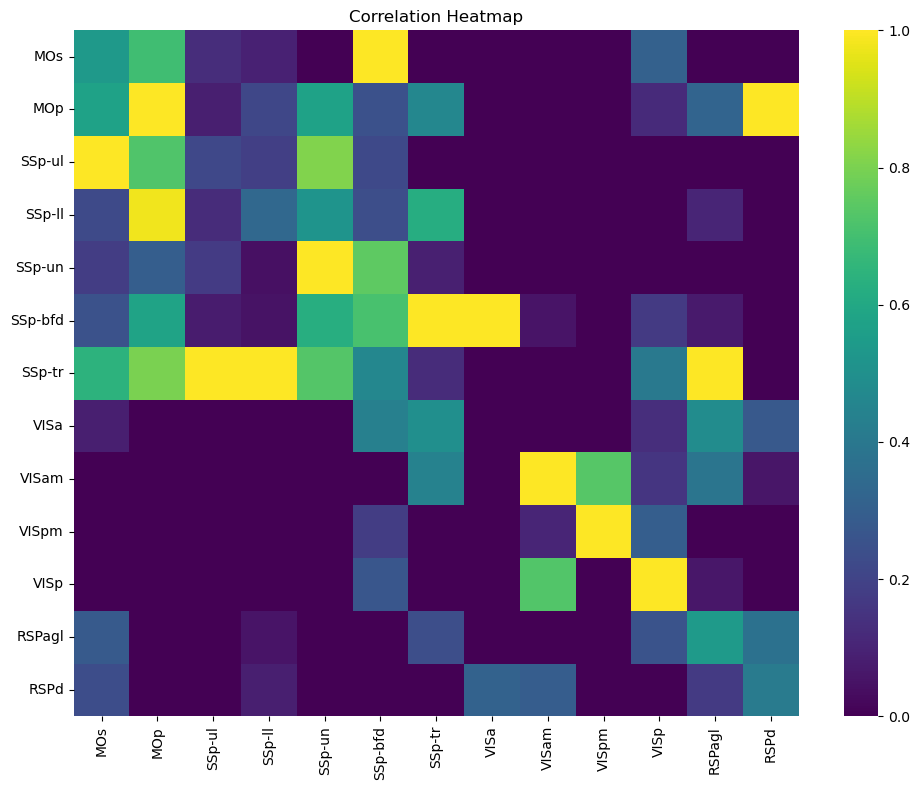

In [14]:
plt.figure(figsize=(10, 8)) 
sns.heatmap(scaled_df, vmin=0, vmax=1, cmap='viridis', annot=False)

plt.title('Correlation Heatmap')
plt.tight_layout()

plt.savefig('SC.tif', format='tiff', dpi=300)
plt.show()

In [15]:
pairs = []

for row in scaled_df.index:
    for col in scaled_df.columns:
        value = scaled_df.at[row, col]
        pairs.append((row, col, value))

pairs_df = pd.DataFrame(pairs, columns=["source", "target", "weight"])
CONNECTED_df = pairs_df[pairs_df['weight'] > 0]
NO_CONNECTED_df = pairs_df[pairs_df['weight'] == 0]
pairs_df

,source,target,weight
0,MOs,MOs,0.538514
1,MOs,MOp,0.693340
2,MOs,SSp-ul,0.126060
3,MOs,SSp-ll,0.091715
4,MOs,SSp-un,0.000000
...,...,...,...
164,RSPd,VISam,0.292741
165,RSPd,VISpm,0.000000
166,RSPd,VISp,0.000000
167,RSPd,RSPagl,0.169734


### 3. Analyse

In [16]:
def get_correlation_matrix_with_labels(correlation_dict, time_stage, unique_area):
    correlation_matrix = correlation_dict.get(time_stage)
    
    if correlation_matrix is None:
        print(f"No data available for time stage {time_stage}")
        return None

    region_labels = [re.sub(r'1$', '', label[0]) for label in unique_area[0]]

    if correlation_matrix.shape[0] != len(region_labels):
        print("Error: Size of correlation matrix does not match number of region labels.")
        return None

    df = pd.DataFrame(correlation_matrix, index=region_labels, columns=region_labels)
    
    return df


correlation_dict, unique_area = calculate_correlation(File_list[0]) #0-4
correlation_df = get_correlation_matrix_with_labels(correlation_dict, 1, unique_area) #0-21
correlation_df

,MOp,MOs,SSp-bfd,SSp-ll,SSp-ul,SSp-tr,SSp-un,VISam,VISp,VISpm,RSPagl,RSPd,VISa,VISrl
MOp,1.000000,0.493687,0.435045,0.509473,0.353478,0.341629,0.390030,0.337021,0.174563,0.223734,0.297524,0.208830,0.156897,0.044206
MOs,0.493687,1.000000,0.271389,0.241348,0.082179,0.295713,0.081088,0.517304,0.278710,0.470773,0.504790,0.534221,0.212917,0.147173
SSp-bfd,0.435045,0.271389,1.000000,0.334985,0.267016,0.408188,0.306347,0.322914,0.234053,0.214595,0.305783,0.161654,0.449804,0.451817
SSp-ll,0.509473,0.241348,0.334985,1.000000,0.552404,0.676130,0.529120,0.430612,0.358607,0.336408,0.313798,0.163071,0.336890,0.109041
SSp-ul,0.353478,0.082179,0.267016,0.552404,1.000000,0.341016,0.617028,0.098535,0.252119,0.104006,0.072652,0.158959,0.002546,0.317116
SSp-tr,0.341629,0.295713,0.408188,0.676130,0.341016,1.000000,0.256026,0.674518,0.511047,0.483583,0.614641,0.237064,0.753260,0.132840
SSp-un,0.390030,0.081088,0.306347,0.529120,0.617028,0.256026,1.000000,0.093249,0.168412,0.142441,0.038350,0.067945,0.000000,0.208468
VISam,0.337021,0.517304,0.322914,0.430612,0.098535,0.674518,0.093249,1.000000,0.581766,0.704550,0.767751,0.409434,0.645505,0.118653
VISp,0.174563,0.278710,0.234053,0.358607,0.252119,0.511047,0.168412,0.581766,1.000000,0.633091,0.565028,0.442300,0.464157,0.404554
VISpm,0.223734,0.470773,0.214595,0.336408,0.104006,0.483583,0.142441,0.704550,0.633091,1.000000,0.741645,0.531370,0.407789,0.194906


In [17]:
from tqdm import tqdm
for file_index in tqdm(range(5), desc='Files'):
    for stage_index in range(22):
        correlation_dict, unique_area = calculate_correlation(File_list[file_index])
        correlation_df = get_correlation_matrix_with_labels(correlation_dict, stage_index, unique_area)
        CONNECTED_df[f'file_{file_index}-stage_{stage_index}'] = [
            correlation_df.loc[src, tgt] for src, tgt in zip(CONNECTED_df['source'], CONNECTED_df['target'])
        ]

Files: 100%|██████████| 5/5 [02:30<00:00, 30.11s/it]


In [18]:
CONNECTED_df.to_pickle('CONNECTED_df.pkl')
CONNECTED_df = pd.read_pickle('CONNECTED_df.pkl')
CONNECTED_df

,source,target,weight,file_0-stage_0,file_0-stage_1,file_0-stage_2,file_0-stage_3,file_0-stage_4,file_0-stage_5,file_0-stage_6,...,file_4-stage_12,file_4-stage_13,file_4-stage_14,file_4-stage_15,file_4-stage_16,file_4-stage_17,file_4-stage_18,file_4-stage_19,file_4-stage_20,file_4-stage_21
0,MOs,MOs,0.538514,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
1,MOs,MOp,0.693340,0.797310,0.493687,0.867021,0.736958,0.947861,0.731973,0.541263,...,0.943109,0.944289,0.924892,0.771024,0.997226,0.918279,0.979006,0.961681,0.978346,0.956109
2,MOs,SSp-ul,0.126060,0.449244,0.082179,0.323831,0.687517,0.975157,0.587890,0.479748,...,0.700668,0.837541,0.915099,0.447090,0.959893,0.815946,0.944487,0.691303,0.745829,0.853184
3,MOs,SSp-ll,0.091715,0.649011,0.241348,0.739750,0.741602,0.940147,0.679395,0.512000,...,0.829300,0.878340,0.943209,0.356660,0.983351,0.808608,0.892710,0.896868,0.917395,0.913190
5,MOs,SSp-bfd,1.000000,0.570307,0.271389,0.416069,0.575919,0.881431,0.552555,0.510571,...,0.934377,0.817838,0.766759,0.589006,0.990219,0.730085,0.910660,0.917785,0.790877,0.840214
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
159,RSPd,SSp-ll,0.085128,0.380292,0.163071,0.755983,0.392421,0.800213,0.053623,0.742183,...,0.495109,0.655987,0.773823,0.601227,0.260466,0.445312,0.858527,0.693206,0.288807,0.740485
163,RSPd,VISa,0.309132,0.400765,0.205384,0.728849,0.071985,0.884045,0.224878,0.749349,...,0.470215,0.445235,0.629088,0.456690,0.293716,0.199608,0.852131,0.682075,0.559818,0.753299
164,RSPd,VISam,0.292741,0.571840,0.409434,0.601477,0.532464,0.924477,0.492631,0.576552,...,0.313843,0.608375,0.493610,0.598342,0.391033,0.393182,0.288048,0.886185,0.511198,0.662410
167,RSPd,RSPagl,0.169734,0.734571,0.612550,0.669558,0.610898,0.903697,0.630546,0.759731,...,0.557210,0.813519,0.594498,0.701266,0.271441,0.602564,0.831686,0.840687,0.464674,0.791851


In [19]:
stage_to_group = {
    1: 'SPON',
    2: 'C1',
    6: 'C2',
    10: 'C3',
    14: 'C4',
    18: 'C5',
    5: 'L1',
    9: 'L2',
    13: 'L3',
    17: 'L4',
    21: 'L5'
}
column_group_map = {}
for col in CONNECTED_df.columns:
    match = re.match(r'file_(\d+)-stage_(\d+)', col)
    if match:
        number1 = int(match.group(1))
        number2 = int(match.group(2))
        if number1 in range(5) and number2 in stage_to_group:
            column_group_map[col] = stage_to_group[number2]

plot_df = pd.DataFrame()
for col, group in column_group_map.items():
    temp_df = pd.DataFrame({
        'Value': CONNECTED_df[col],
        'Group': group
    })
    plot_df = pd.concat([plot_df, temp_df], ignore_index=True)

plot_df

,Value,Group
0,1.000000,SPON
1,0.493687,SPON
2,0.082179,SPON
3,0.241348,SPON
4,0.271389,SPON
...,...,...
4890,0.740485,L5
4891,0.753299,L5
4892,0.662410,L5
4893,0.791851,L5


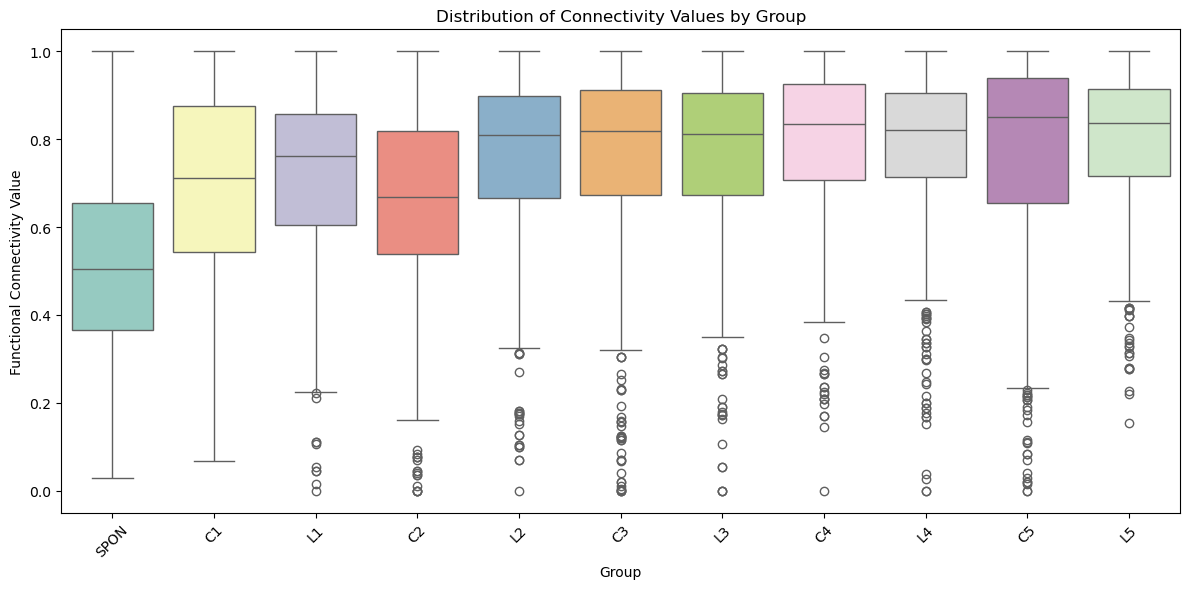

In [20]:
plt.figure(figsize=(12, 6))
sns.boxplot(x='Group', y='Value', data=plot_df, palette='Set3')
plt.title('Distribution of Connectivity Values by Group')
plt.xlabel('Group')
plt.ylabel('Functional Connectivity Value')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

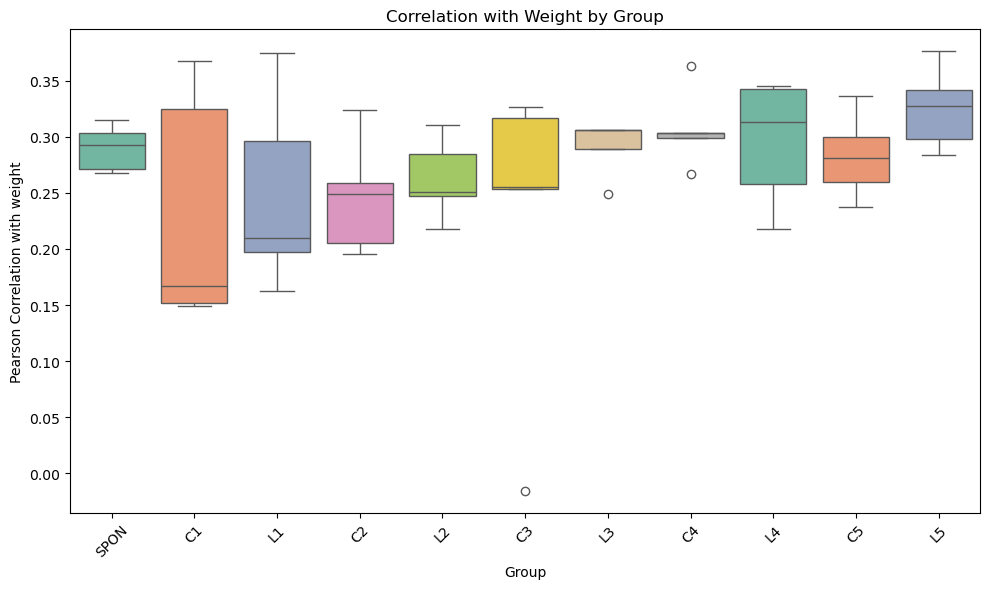

In [21]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import re

# 分组规则
stage_to_group = {
    1: 'SPON',
    2: 'C1',
    6: 'C2',
    10: 'C3',
    14: 'C4',
    18: 'C5',
    5: 'L1',
    9: 'L2',
    13: 'L3',
    17: 'L4',
    21: 'L5'
}

# 生成列名 -> group 映射
column_group_map = {}
for col in CONNECTED_df.columns:
    match = re.match(r'file_(\d+)-stage_(\d+)', col)
    if match:
        number1 = int(match.group(1))
        number2 = int(match.group(2))
        if number1 in range(5) and number2 in stage_to_group:
            column_group_map[col] = stage_to_group[number2]

# 构建 group -> list of correlation 的字典
group_corr_values = {}

for col, group in column_group_map.items():
    corr = CONNECTED_df[col].corr(CONNECTED_df['weight'])  # 计算每列与 weight 的 Pearson 相关性
    group_corr_values.setdefault(group, []).append(corr)

# 整理为绘图 DataFrame
corr_plot_df = pd.DataFrame([
    {'Group': group, 'Correlation': corr}
    for group, corr_list in group_corr_values.items()
    for corr in corr_list
])

# 绘图
plt.figure(figsize=(10, 6))
sns.boxplot(x='Group', y='Correlation', data=corr_plot_df, palette='Set2')
plt.title('Correlation with Weight by Group')
plt.ylabel('Pearson Correlation with weight')
plt.xlabel('Group')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


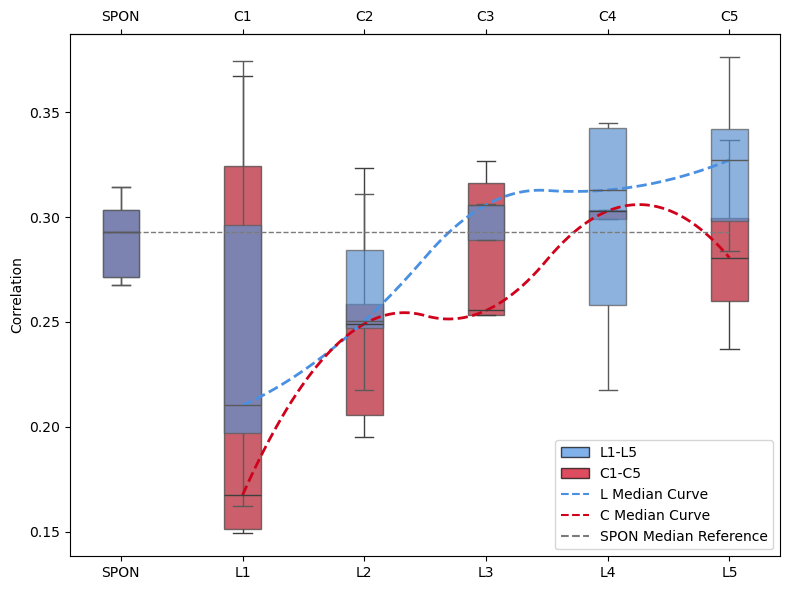

In [37]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import make_interp_spline
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

L_color = '#4A90E2'     # 高级蓝（L1-L5）
C_color = '#D0021B'     # 高级红（C1-C5）
SPON_color = '#7B7B7B'  # 高端灰（SPON）

L_labels = ['SPON', 'L1', 'L2', 'L3', 'L4', 'L5']
C_labels = ['SPON', 'C1', 'C2', 'C3', 'C4', 'C5']
positions = list(range(len(L_labels)))

group_to_pos = {l: i for i, l in enumerate(L_labels)}
group_to_pos.update({c: i for i, c in enumerate(C_labels)})

corr_plot_df['Position'] = corr_plot_df['Group'].map(group_to_pos)

df_L = corr_plot_df[corr_plot_df['Group'].str.match(r'^L\d$|^SPON$')]
df_C = corr_plot_df[corr_plot_df['Group'].str.match(r'^C\d$|^SPON$')]

plt.figure(figsize=(8, 6))
ax = plt.gca()

sns.boxplot(
    x='Position',
    y='Correlation',
    data=df_C,
    ax=ax,
    width=0.3,
    color=C_color,
    boxprops=dict(alpha=0.7),
    showfliers=False
)

sns.boxplot(
    x='Position',
    y='Correlation',
    data=df_L,
    ax=ax,
    width=0.3,
    color=L_color,
    boxprops=dict(alpha=0.7),
    showfliers=False
)

medians_L = df_L.groupby('Position')['Correlation'].median().sort_index()
medians_C = df_C.groupby('Position')['Correlation'].median().sort_index()

medians_L_no_SPON = medians_L.drop(index=0)
medians_C_no_SPON = medians_C.drop(index=0)

def smooth_line(x, y, points=300):
    if len(x) < 3:
        return x, y
    x_new = np.linspace(min(x), max(x), points)
    spline = make_interp_spline(x, y, k=2)
    y_smooth = spline(x_new)
    return x_new, y_smooth

x_L, y_L = smooth_line(medians_L_no_SPON.index, medians_L_no_SPON.values)
ax.plot(x_L, y_L, color=L_color, linestyle='--', linewidth=2)

x_C, y_C = smooth_line(medians_C_no_SPON.index, medians_C_no_SPON.values)
ax.plot(x_C, y_C, color=C_color, linestyle='--', linewidth=2)

spon_median_L = df_L[df_L['Position'] == 0]['Correlation'].median()
spon_median_C = df_C[df_C['Position'] == 0]['Correlation'].median()
spon_median = np.mean([spon_median_L, spon_median_C])

x_min = min(positions)
x_max = max(positions)

ax.hlines(y=spon_median, xmin=x_min, xmax=x_max, colors=SPON_color, 
          linestyles='--', linewidth=1)

ax.set_xticks(positions)
ax.set_xticklabels(L_labels)
ax.set_xlabel("")

secax = ax.secondary_xaxis('top')
secax.set_xticks(positions)
secax.set_xticklabels(C_labels)

ax.set_ylabel("Correlation")

legend_elements = [
    Patch(facecolor=L_color, edgecolor='black', alpha=0.7, label='L1-L5'),
    Patch(facecolor=C_color, edgecolor='black', alpha=0.7, label='C1-C5'),
    Line2D([0], [0], color=L_color, linestyle='--', label='L Median Curve'),
    Line2D([0], [0], color=C_color, linestyle='--', label='C Median Curve'),
    Line2D([0], [0], color=SPON_color, linestyle='--', label='SPON Median Reference')
]
ax.legend(handles=legend_elements)

plt.tight_layout()
plt.savefig('FC-SC_correlation.pdf', format='pdf', dpi=300)
plt.show()


In [24]:
from tqdm import tqdm
for file_index in tqdm(range(5), desc='Files'):
    for stage_index in range(22):
        correlation_dict, unique_area = calculate_correlation(File_list[file_index])
        correlation_df = get_correlation_matrix_with_labels(correlation_dict, stage_index, unique_area)
        NO_CONNECTED_df[f'file_{file_index}-stage_{stage_index}'] = [
            correlation_df.loc[src, tgt] for src, tgt in zip(NO_CONNECTED_df['source'], NO_CONNECTED_df['target'])
        ]

Files: 100%|██████████| 5/5 [02:33<00:00, 30.77s/it]


In [25]:
NO_CONNECTED_df.to_pickle('NO_CONNECTED_df.pkl')
NO_CONNECTED_df = pd.read_pickle('NO_CONNECTED_df.pkl')
NO_CONNECTED_df

,source,target,weight,file_0-stage_0,file_0-stage_1,file_0-stage_2,file_0-stage_3,file_0-stage_4,file_0-stage_5,file_0-stage_6,...,file_4-stage_12,file_4-stage_13,file_4-stage_14,file_4-stage_15,file_4-stage_16,file_4-stage_17,file_4-stage_18,file_4-stage_19,file_4-stage_20,file_4-stage_21
4,MOs,SSp-un,0.0,0.234895,0.081088,0.340701,0.698060,0.167048,0.590097,0.755359,...,0.642028,0.715882,0.742579,0.541542,0.982266,0.728865,0.916586,0.779299,0.959469,0.754958
6,MOs,SSp-tr,0.0,0.504553,0.295713,0.633649,0.564743,0.986362,0.765651,0.662844,...,0.931420,0.864030,0.955417,0.599564,0.981913,0.763378,0.885449,0.808573,0.862015,0.872311
7,MOs,VISa,0.0,0.501862,0.212917,0.738551,0.154857,0.987798,0.754630,0.369947,...,0.915713,0.837046,0.745510,0.506279,0.976514,0.469411,0.915524,0.851798,0.689386,0.844936
8,MOs,VISam,0.0,0.709325,0.517304,0.677491,0.311723,0.948296,0.793044,0.461715,...,0.915889,0.746524,0.479808,0.518901,0.953506,0.586277,0.592370,0.889142,0.819983,0.737755
9,MOs,VISpm,0.0,0.557317,0.470773,0.594621,0.295946,0.821751,0.782533,0.592251,...,0.718404,0.221244,0.153784,0.165286,0.914260,0.388647,0.255541,0.641564,0.541067,0.332037
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
160,RSPd,SSp-un,0.0,0.221300,0.067945,0.456523,0.625326,0.149250,0.268613,0.572830,...,0.000000,0.599609,0.697519,0.432647,0.000000,0.000000,0.840137,0.669415,0.000000,0.463441
161,RSPd,SSp-bfd,0.0,0.460845,0.161654,0.528621,0.289217,0.867699,0.168233,0.670475,...,0.398325,0.518068,0.775229,0.247044,0.109629,0.194745,0.793064,0.859115,0.057419,0.660416
162,RSPd,SSp-tr,0.0,0.418664,0.237064,0.595650,0.478344,0.869138,0.295744,0.837084,...,0.399029,0.589513,0.756522,0.512441,0.172339,0.137021,0.811386,0.599982,0.422985,0.736765
165,RSPd,VISpm,0.0,0.356818,0.531370,0.524399,0.307745,0.816905,0.348569,0.225986,...,0.563905,0.478501,0.294844,0.360388,0.479097,0.522961,0.165515,0.634809,0.526214,0.448608


In [26]:
stage_to_group = {
    1: 'SPON',
    2: 'C1',
    6: 'C2',
    10: 'C3',
    14: 'C4',
    18: 'C5',
    5: 'L1',
    9: 'L2',
    13: 'L3',
    17: 'L4',
    21: 'L5'
}
column_group_map = {}
for col in NO_CONNECTED_df.columns:
    match = re.match(r'file_(\d+)-stage_(\d+)', col)
    if match:
        number1 = int(match.group(1))
        number2 = int(match.group(2))
        if number1 in range(5) and number2 in stage_to_group:
            column_group_map[col] = stage_to_group[number2]

plot_df2 = pd.DataFrame()
for col, group in column_group_map.items():
    temp_df = pd.DataFrame({
        'Value': NO_CONNECTED_df[col],
        'Group': group
    })
    plot_df2 = pd.concat([plot_df2, temp_df], ignore_index=True)

plot_df2

,Value,Group
0,0.081088,SPON
1,0.295713,SPON
2,0.212917,SPON
3,0.517304,SPON
4,0.470773,SPON
...,...,...
4395,0.463441,L5
4396,0.660416,L5
4397,0.736765,L5
4398,0.448608,L5


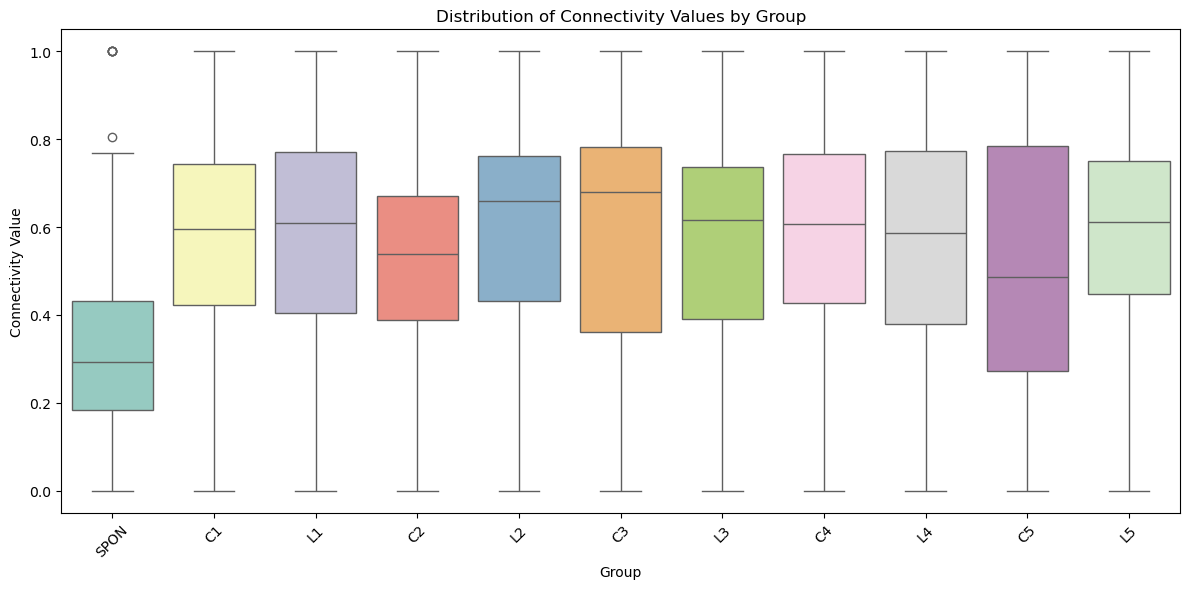

In [27]:
plt.figure(figsize=(12, 6))
sns.boxplot(x='Group', y='Value', data=plot_df2, palette='Set3')
plt.title('Distribution of Connectivity Values by Group')
plt.xlabel('Group')
plt.ylabel('Connectivity Value')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [28]:
plot_df

,Value,Group
0,1.000000,SPON
1,0.493687,SPON
2,0.082179,SPON
3,0.241348,SPON
4,0.271389,SPON
...,...,...
4890,0.740485,L5
4891,0.753299,L5
4892,0.662410,L5
4893,0.791851,L5


In [29]:
import pandas as pd
import numpy as np
from scipy.stats import ttest_ind
import matplotlib.pyplot as plt
import seaborn as sns

results = []
groups = plot_df['Group'].unique()


for group in groups:
    values1 = plot_df[plot_df['Group'] == group]['Value']
    values2 = plot_df2[plot_df2['Group'] == group]['Value']
    
    if values1.empty or values2.empty:
        continue
    
    median_diff = values1.median() - values2.median()
    mean_diff = values1.mean() - values2.mean()  # 计算平均值差
    
    try:
        stat, pval = ttest_ind(values1, values2, equal_var=False)
    except:
        pval = 1.0
    
    results.append({
        'Group': group,
        'MedianDiff': median_diff,
        'MeanDiff': mean_diff,  # 新增一列
        'PValue': pval,
        '-log10(P)': -np.log10(pval + 1e-10)
    })

res_df = pd.DataFrame(results)
res_df

,Group,MedianDiff,MeanDiff,PValue,-log10(P)
0,SPON,0.212691,0.220884,1.567676e-43,10.000000
1,C1,0.117486,0.125976,5.127213e-16,9.999998
2,L1,0.153266,0.161443,6.182459e-24,10.000000
3,C2,0.130120,0.144727,6.523233e-20,10.000000
4,L2,0.150392,0.164212,1.853839e-24,10.000000
5,C3,0.138677,0.156705,2.402031e-19,10.000000
6,L3,0.196794,0.195336,1.655555e-34,10.000000
7,C4,0.227710,0.222084,1.019910e-42,10.000000
8,L4,0.234229,0.215341,1.603412e-39,10.000000
9,C5,0.364544,0.250364,1.079662e-37,10.000000


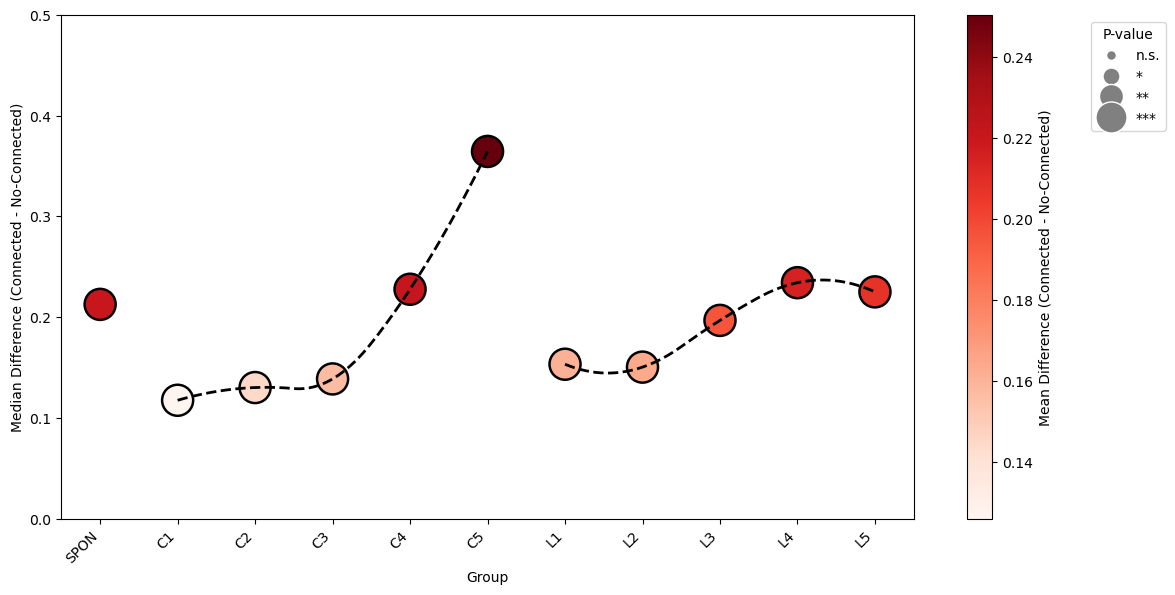

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
from scipy.interpolate import make_interp_spline

def categorize_p_symbol(p):
    if p > 0.05:
        return 'n.s.'
    elif p > 0.01:
        return '*'
    elif p > 0.001:
        return '**'
    else:
        return '***'

group_order = ['SPON', 'C1', 'C2', 'C3', 'C4', 'C5', 'L1', 'L2', 'L3', 'L4', 'L5']
res_df['Group'] = pd.Categorical(res_df['Group'], categories=group_order, ordered=True)
res_df['P_bin'] = res_df['PValue'].apply(categorize_p_symbol)

size_dict = {
    'n.s.': 50,
    '*': 150,
    '**': 300,
    '***': 500
}
size_order = list(size_dict.keys())

fig, ax = plt.subplots(figsize=(12, 6))

sns.scatterplot(
    data=res_df,
    x='Group',
    y='MedianDiff',
    size='P_bin',
    hue='MeanDiff',
    palette='Reds',
    sizes=size_dict,
    size_order=size_order,
    edgecolor='black',
    ax=ax,
    legend=False
)

ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.set_xlabel('Group')
ax.set_ylabel('Median Difference (Connected - No-Connected)')

norm = plt.Normalize(res_df['MeanDiff'].min(), res_df['MeanDiff'].max())
sm = plt.cm.ScalarMappable(cmap='Reds', norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax)
cbar.set_label('Mean Difference (Connected - No-Connected)')

size_legend = [
    Line2D([0], [0], marker='o', color='w', label=label,
           markerfacecolor='gray', markersize=np.sqrt(size))
    for label, size in size_dict.items()
]
ax.legend(handles=size_legend, bbox_to_anchor=(1.2, 1), loc='upper left', title='P-value')

def add_smooth_curve(ax, df, groups, color='black', linestyle='--'):
    sub = df[df['Group'].isin(groups)].copy()
    sub = sub.sort_values('Group')
    xtick_labels = [t.get_text() for t in ax.get_xticklabels()]
    xtick_positions = ax.get_xticks()
    x_map = dict(zip(xtick_labels, xtick_positions))
    x = np.array([x_map[g] for g in sub['Group']])
    y = sub['MedianDiff'].values
    if len(x) >= 3:
        x_new = np.linspace(x.min(), x.max(), 300)
        spline = make_interp_spline(x, y, k=2)
        y_new = spline(x_new)
        ax.plot(x_new, y_new, color=color, linestyle=linestyle, linewidth=2)
    else:
        ax.plot(x, y, color=color, linestyle=linestyle, linewidth=2)

add_smooth_curve(ax, res_df, ['C1', 'C2', 'C3', 'C4', 'C5'], color='black', linestyle='--')
add_smooth_curve(ax, res_df, ['L1', 'L2', 'L3', 'L4', 'L5'], color='black', linestyle='--')

plt.tight_layout()
plt.ylim(0, 0.5)
plt.savefig('Connected_No-connected_difference.pdf', format='pdf', dpi=300)
plt.show()


## Plot SC

In [43]:
df_layers = pd.read_excel('../BWM/SEU_net_wo_corticalLayers.xlsx', header=1, index_col=1)
df_layers = df_layers.iloc[:, 1:]
scaler = MinMaxScaler()
df_scaled = pd.DataFrame(
    scaler.fit_transform(df_layers),
    index=df_layers.index,
    columns=df_layers.columns
)

df_scaled

,FRP,MOp,MOs,SSp-n,SSp-bfd,SSp-ll,SSp-m,SSp-ul,SSp-tr,SSp-un,...,MD,SMT,PVT,RE,CM,RT,PSV,PB,TRN,PRNr
FRP,0.000000,0.000000,0.614604,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000
MOp,0.441167,0.378662,0.534982,0.281224,0.237631,0.211517,0.242158,0.083040,0.402819,0.297850,...,0.000000,0.000000,0.0,0.0,0.0,0.372428,0.0,0.0,0.0,0.720896
MOs,1.000000,0.262542,0.498483,0.202547,0.954544,0.091715,0.286042,0.126060,0.000000,0.000000,...,0.000000,0.208482,0.0,0.0,0.0,0.332571,0.0,0.0,0.0,0.000000
SSp-n,0.000000,0.150043,0.388819,0.542448,0.455849,0.000000,0.460327,0.209069,0.000000,0.358855,...,0.000000,0.000000,0.0,0.0,0.0,0.350530,0.0,0.0,0.0,0.000000
SSp-bfd,0.000000,0.220388,0.232333,0.504613,0.677445,0.048127,0.275838,0.075778,0.872903,0.324635,...,0.000000,0.000000,0.0,0.0,0.0,0.082808,0.0,0.0,0.0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RT,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.477782,0.274014,0.0,1.0,0.0,0.329808,0.0,0.0,0.0,0.000000
PSV,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.593837
PB,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,1.000000
TRN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000


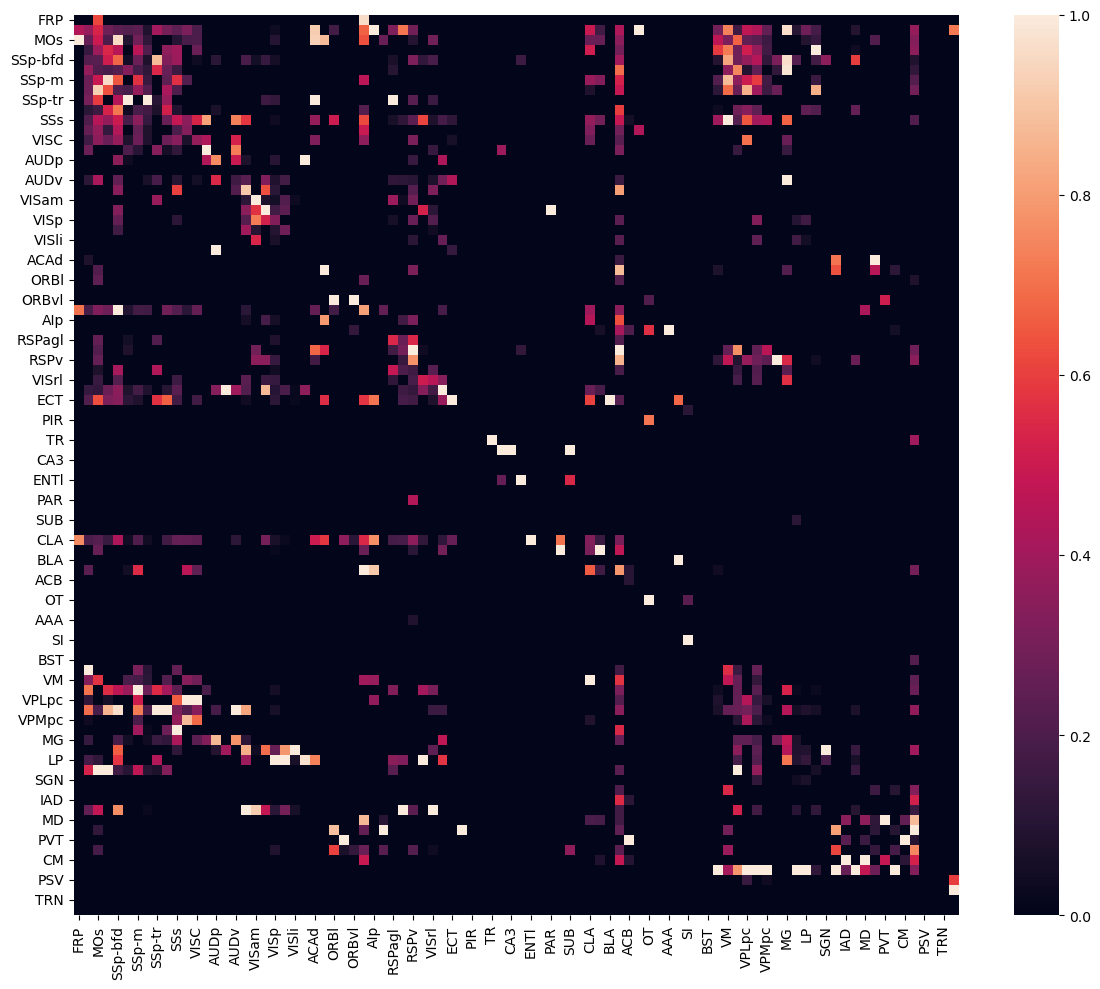

In [50]:
plt.figure(figsize=(12, 10))
sns.heatmap(df_scaled, cmap='rocket', linewidths=0)
plt.title("", fontsize=16)
plt.tight_layout()
plt.savefig("heatmap_wo_layers.pdf", format='pdf', dpi=300, bbox_inches='tight')
plt.show()

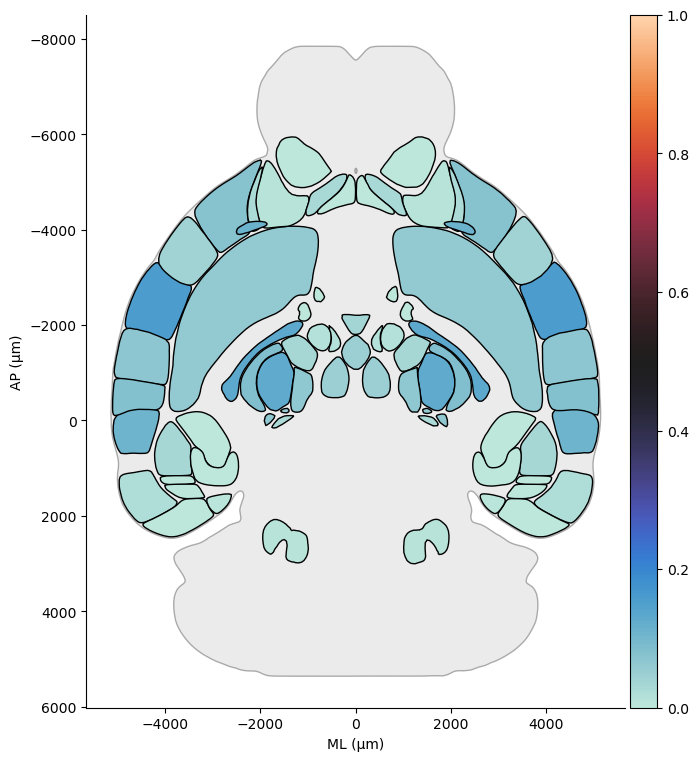

In [54]:
import brainglobe_heatmap as bgh

values = df_scaled.mean(axis=1).to_dict()

# draw brainglobe heatmap
heatmap = bgh.Heatmap(
    values=values,
    position=None,
    orientation="horizontal",
    thickness=1000,
    atlas_name="allen_mouse_25um",
    vmin=0,
    vmax=1,
    cmap="icefire",
    format="2D",
).show(xlabel='ML (μm)', ylabel='AP (μm)')

In [55]:
df_no_layers = pd.read_excel('../BWM/SEU_net_w_corticalLayers.xlsx', header=1, index_col=1)
df_no_layers = df_no_layers.iloc[:, 1:]
scaler = MinMaxScaler()
df_scaled2 = pd.DataFrame(
    scaler.fit_transform(df_no_layers),
    index=df_no_layers.index,
    columns=df_no_layers.columns
)

df_scaled2

,FRP2/3,MOp1,MOp2/3,MOp5,MOp6a,MOs1,MOs2/3,MOs5,MOs6a,SSp-n2/3,...,MD,SMT,PVT,RE,CM,RT,PSV,PB,TRN,PRNr
FRP2/3,0.000000,0.0,0.000000,0.000000,0.000000,0.331930,0.421616,0.600585,0.0,0.000000,...,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000
MOp1,0.000000,0.0,0.157859,0.293038,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000
MOp2/3,0.413603,0.0,0.228551,0.257367,0.643928,0.284388,0.274564,0.528111,0.0,0.028615,...,0.000000,0.000000,0.0,0.0,0.0,0.403550,0.0,0.0,0.0,0.720896
MOp5,0.000000,0.0,0.117454,0.435530,0.558187,0.162700,0.400272,0.764195,0.0,0.000000,...,0.000000,0.000000,0.0,0.0,0.0,0.343516,0.0,0.0,0.0,0.000000
MOp6a,0.000000,0.0,0.253475,0.059824,0.787805,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,0.000000,0.0,0.0,0.0,0.396918,0.0,0.0,0.0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RT,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.477782,0.274014,0.0,1.0,0.0,0.329808,0.0,0.0,0.0,0.000000
PSV,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.593837
PB,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,1.000000
TRN,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000


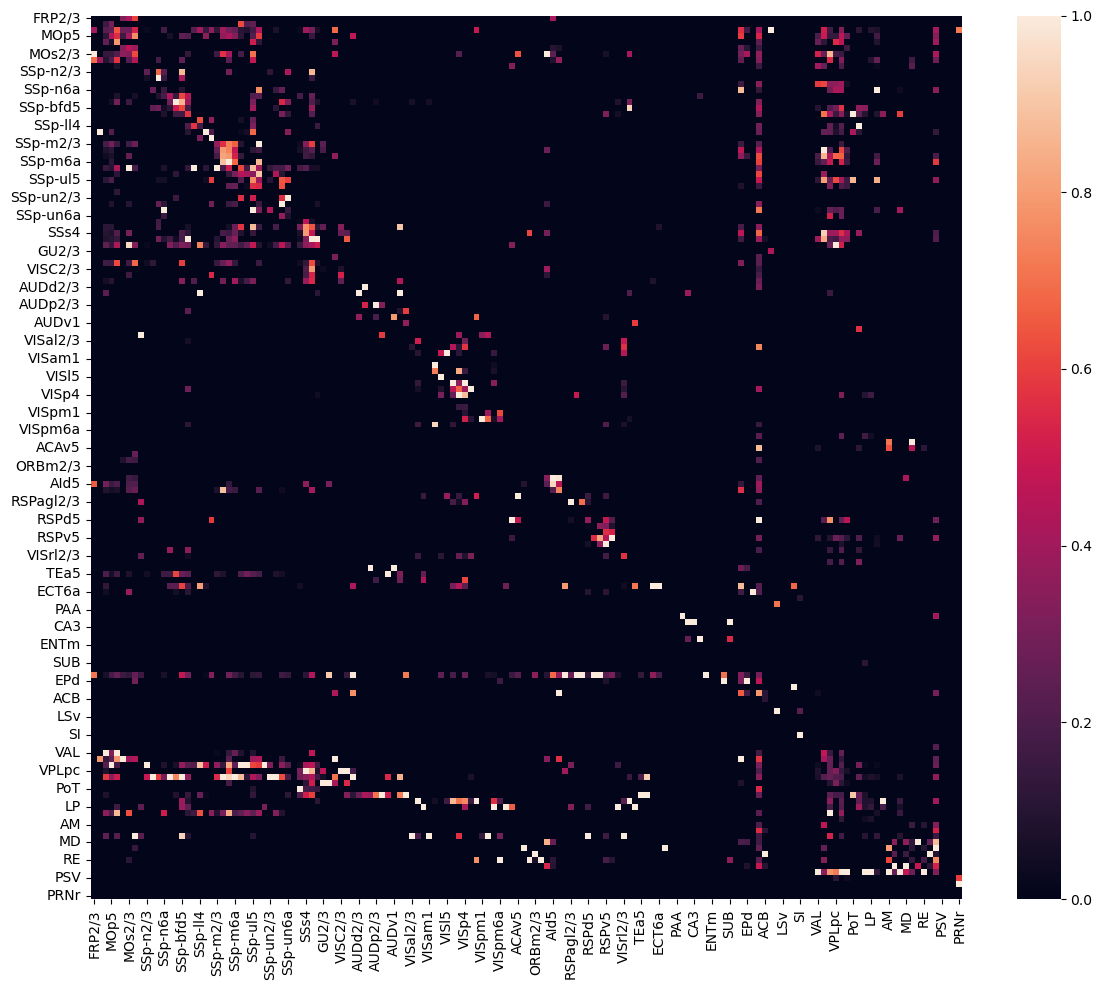

In [60]:
plt.figure(figsize=(12, 10))
sns.heatmap(df_scaled2, cmap='rocket', linewidths=0)
plt.title("", fontsize=16)
plt.tight_layout()
plt.savefig("heatmap_w_layers.pdf", format='pdf', dpi=300, bbox_inches='tight')
plt.show()

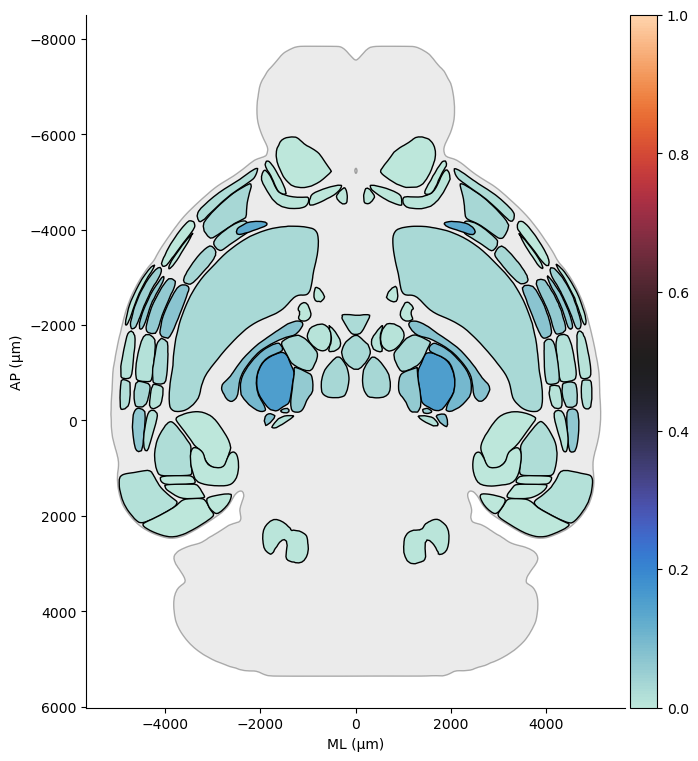

In [61]:
import brainglobe_heatmap as bgh

values = df_scaled2.mean(axis=1).to_dict()

# draw brainglobe heatmap
heatmap = bgh.Heatmap(
    values=values,
    position=None,
    orientation="horizontal",
    thickness=1000,
    atlas_name="allen_mouse_25um",
    vmin=0,
    vmax=1,
    cmap="icefire",
    format="2D",
).show(xlabel='ML (μm)', ylabel='AP (μm)')